# 🧠 How Large Language Models Work
### A hands-on session — no heavy math, real tools

We use **ready-made libraries** (`tiktoken`, `transformers`, `sentence-transformers`) instead of building things by hand, so we can focus on *what's happening and why it matters*.

**How to run:** open in Google Colab → *Runtime ▸ Run all* once beforehand (downloads models), then step through live.
💬 = a discussion question to ask the class.

---

## 🗺️ Agenda

| # | Section | Time | Path |
|---|---------|------|------|
| 0 | Setup | 3 min | ⭐ |
| 1 | The big picture | 5 min | ⭐ |
| 2 | Tokens: how text becomes numbers | 6 min | ⭐ |
| 3 | Embeddings: how numbers get meaning | 7 min | 🔷 |
| 4 | Attention: how words look at each other | 6 min | ⭐ |
| 5 | The Transformer architecture | 4 min | ⭐ |
| 6 | Predicting the next word & controlling creativity | 8 min | ⭐ |
| 7 | From raw model to chat assistant | 8 min | ⭐ |
| 8 | Scale: size, memory, cost | 5 min | 🔷 |
| 9 | Limitations: why LLMs get things wrong | 6 min | ⭐ |
| 10 | RAG & agents: making LLMs more useful | 8 min | 🔷 |
| 11 | Recap & exercises | 4 min | ⭐ |

⭐ core ≈ 50 min · 🔷 extras bring it to ≈ 70 min
⏱️ **Only 30 minutes?** Run sections **0, 1, 2, 4, 6, 11**.

## 0️⃣ Setup

In [9]:
import os
from pathlib import Path

# Keep model downloads on the project drive; C: has limited space.
PROJECT_DIR = Path(os.environ.get('NOTEBOOK_PROJECT_DIR', Path.cwd())).resolve()
MODEL_CACHE = PROJECT_DIR / '.model_cache'
MODEL_CACHE.mkdir(parents=True, exist_ok=True)
print('Model cache:', MODEL_CACHE)
os.environ['HF_HUB_DISABLE_XET'] = '1'
os.environ['HF_HUB_CACHE'] = str(MODEL_CACHE)

# Install missing packages into the Python environment used by this notebook.
import importlib.util
import subprocess
import sys

packages = {
    'numpy': 'numpy', 'matplotlib': 'matplotlib', 'tiktoken': 'tiktoken',
    'transformers': 'transformers', 'torch': 'torch',
    'sentence_transformers': 'sentence-transformers', 'sklearn': 'scikit-learn',
    'anthropic': 'anthropic',
}
missing = [package for module, package in packages.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *missing])
print('Dependencies ready in:', sys.executable)


Model cache: D:\Sunday_Office_Class\class_10_8_26_AI LLM Foundations\.model_cache
Dependencies ready in: d:\Sunday_Office_Class\class_10_8_26_AI LLM Foundations\.venv\Scripts\python.exe


In [10]:
import math, textwrap
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PALETTE = ["#4C78A8", "#F58518", "#54A24B", "#B279A2", "#E45756", "#72B7B2", "#EECA3B"]

def flow(labels, title=None, per_row=5, wrap=16, colors=None):
    """Draws a simple flowchart (boxes + arrows). Just a drawing helper."""
    n = len(labels); rows = math.ceil(n / per_row)
    w, h, dx, dy = 1.8, 0.9, 2.3, 1.7
    cols = min(n, per_row)
    fig, ax = plt.subplots(figsize=(dx * cols * 0.95, dy * rows * 0.8 + 0.5))
    ax.set_xlim(-0.2, dx * cols); ax.set_ylim(-0.2, dy * rows); ax.axis("off")
    pal = colors or PALETTE
    pos = []
    for i, lab in enumerate(labels):
        r, c = divmod(i, per_row)
        x, y = c * dx, (rows - 1 - r) * dy + 0.3
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.03,rounding_size=0.15",
                                    fc=pal[i % len(pal)], ec="none", alpha=0.92))
        ax.text(x + w / 2, y + h / 2, textwrap.fill(lab, wrap), ha="center", va="center",
                color="white", fontsize=9, fontweight="bold")
        pos.append((x, y))
    for (x1, y1), (x2, y2) in zip(pos, pos[1:]):
        if y1 == y2: a, b = (x1 + w, y1 + h / 2), (x2, y2 + h / 2)
        else:        a, b = (x1 + w / 2, y1), (x2 + w / 2, y2 + h)
        ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", lw=1.6, color="#444"))
    if title: ax.set_title(title, fontweight="bold")
    plt.show()

def stack(labels, title=None, colors=None):
    """Vertical diagram; labels listed BOTTOM -> TOP (data flows upward)."""
    n = len(labels); pal = colors or PALETTE
    fig, ax = plt.subplots(figsize=(6, 0.85 * n + 0.6))
    ax.axis("off"); ax.set_xlim(0, 5); ax.set_ylim(0, n)
    for i, lab in enumerate(labels):
        y = i + 0.1
        ax.add_patch(FancyBboxPatch((0.4, y), 4.2, 0.6, boxstyle="round,pad=0.02,rounding_size=0.12",
                                    fc=pal[i % len(pal)], ec="none", alpha=0.92))
        ax.text(2.5, y + 0.3, lab, ha="center", va="center", color="white", fontsize=9.5, fontweight="bold")
        if i < n - 1:
            ax.annotate("", xy=(2.5, y + 1.0), xytext=(2.5, y + 0.62),
                        arrowprops=dict(arrowstyle="-|>", lw=1.5, color="#444"))
    if title: ax.set_title(title, fontweight="bold")
    plt.show()
print("✅ helpers ready")

✅ helpers ready


We'll use **GPT-2** (a small, open model from 2019) as our "lab specimen". It has the same basic design as today's giants, just smaller — so it runs on a free laptop/Colab.

In [11]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, pipeline, set_seed

tok  = AutoTokenizer.from_pretrained("gpt2", cache_dir=str(MODEL_CACHE))
gpt2 = AutoModelForCausalLM.from_pretrained("gpt2", attn_implementation="eager", cache_dir=str(MODEL_CACHE)).eval()
generator = pipeline("text-generation", model=gpt2, tokenizer=tok)
print("GPT-2 loaded ✅")

Loading weights: 100%|██████████| 148/148 [00:01<00:00, 88.26it/s]

GPT-2 loaded ✅


---
## 1️⃣ The big picture

> **An LLM is a program that reads text and predicts the most likely next piece of text.**

Do that repeatedly and you get paragraphs, answers, code, and conversations.

```
"The capital of France is"  ──►  [ LLM ]  ──►  " Paris" (82%)   " the" (4%)   " a" (2%) ...
```

D:\Sunday_Office_Class\class_10_8_26_AI LLM Foundations\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128257 (\N{CLOCKWISE RIGHTWARDS AND LEFTWARDS OPEN CIRCLE ARROWS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


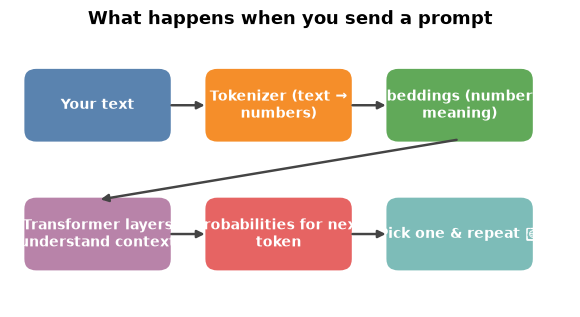

In [4]:
flow(["Your text", "Tokenizer\n(text → numbers)", "Embeddings\n(numbers → meaning)",
      "Transformer layers\n(understand context)", "Probabilities for\nnext token", "Pick one & repeat 🔁"],
     title="What happens when you send a prompt", per_row=3, wrap=22)

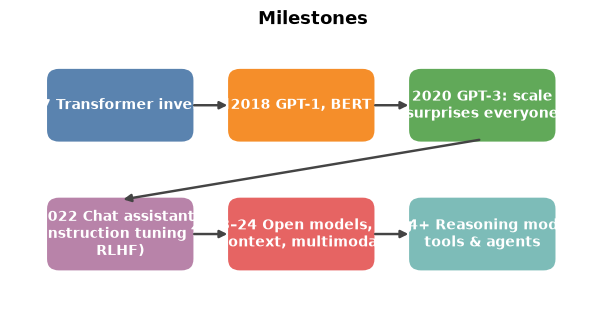

In [5]:
flow(["2017\nTransformer\ninvented", "2018\nGPT-1, BERT", "2020\nGPT-3:\nscale surprises everyone",
      "2022\nChat assistants\n(instruction tuning + RLHF)", "2023–24\nOpen models,\nlong context, multimodal",
      "2024+\nReasoning models,\ntools & agents"],
     title="Milestones", per_row=3, wrap=26)

💬 **Discussion:** If it only predicts the next word, why can it answer questions or write code?
*(To predict text well across the internet, it has to pick up facts, grammar, logic and style along the way.)*

---
## 2️⃣ Tokens: how text becomes numbers

Computers can't read words, only numbers. A **tokenizer** chops text into small pieces called **tokens** (whole words, word-parts, or punctuation) and gives each an ID number.

Rule of thumb: **1 token ≈ ¾ of an English word.**

In [6]:
import tiktoken
enc = tiktoken.get_encoding("cl100k_base")      # tokenizer used by many modern models

def show_tokens(text):
    ids = enc.encode(text)
    print(f"{text!r}\n  → {len(ids)} tokens: {[enc.decode([i]) for i in ids]}\n")

for t in ["Hello world", "unbelievably", "ChatGPT is amazing!", "12345678"]:
    show_tokens(t)

'Hello world'
  → 2 tokens: ['Hello', ' world']

'unbelievably'
  → 3 tokens: ['un', 'belie', 'vably']

'ChatGPT is amazing!'
  → 6 tokens: ['Chat', 'G', 'PT', ' is', ' amazing', '!']

'12345678'
  → 3 tokens: ['123', '456', '78']



**Notice:** common words are one token; rare words get split into pieces; numbers get chopped up.

### Why this matters: *tokens = money & memory*
Models charge by token and have a limit on how many tokens they can handle at once (the **context window**). Not all languages are equally efficient:

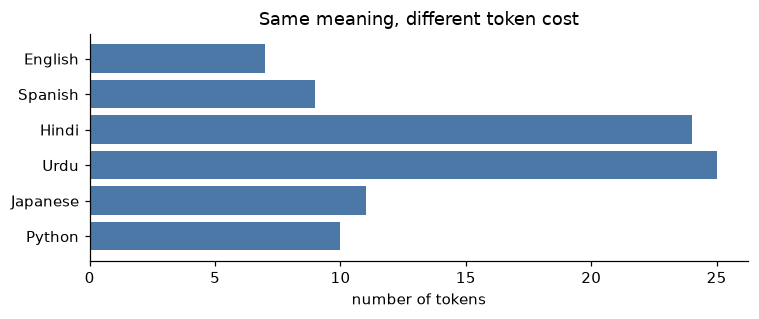

In [7]:
samples = {
    "English":  "Hello, how are you today?",
    "Spanish":  "Hola, ¿cómo estás hoy?",
    "Hindi":    "नमस्ते, आप आज कैसे हैं?",
    "Urdu":     "ہیلو، آپ آج کیسے ہیں؟",
    "Japanese": "こんにちは、今日はお元気ですか？",
    "Python":   "def add(a, b): return a + b",
}
counts = {k: len(enc.encode(v)) for k, v in samples.items()}
plt.figure(figsize=(7, 3))
plt.barh(list(counts)[::-1], list(counts.values())[::-1], color=PALETTE[0])
plt.xlabel("number of tokens"); plt.title("Same meaning, different token cost")
plt.tight_layout(); plt.show()

💬 **Discussion:** What does this mean for users who write in languages that need more tokens?
*(Higher cost, less room in the context window, often weaker performance.)*

<details><summary>How are tokenizer pieces chosen? (optional)</summary>
Most tokenizers use <b>Byte-Pair Encoding</b>: start with single characters and repeatedly merge the most common neighbouring pairs until the vocabulary reaches a target size (typically 30k–200k tokens).
</details>

---
## 3️⃣ Embeddings: how numbers get meaning 🔷

Each token ID is turned into a long list of numbers (a **vector**, often hundreds or thousands long) that captures *meaning*. Similar meanings → vectors that sit close together.

Let's try this with a ready-made embedding model.

In [8]:
from sentence_transformers import SentenceTransformer
embedder = SentenceTransformer("all-MiniLM-L6-v2", cache_folder=str(MODEL_CACHE))      # small, fast embedding model

sentences = ["The cat sat on the mat.", "A kitten is resting on the rug.",
             "The stock market fell sharply today.", "Shares dropped as investors panicked.",
             "I love eating pizza.", "Pasta is my favourite food."]
emb = embedder.encode(sentences, normalize_embeddings=True)
print("each sentence → a vector of", emb.shape[1], "numbers")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1240.96it/s]

each sentence → a vector of 384 numbers


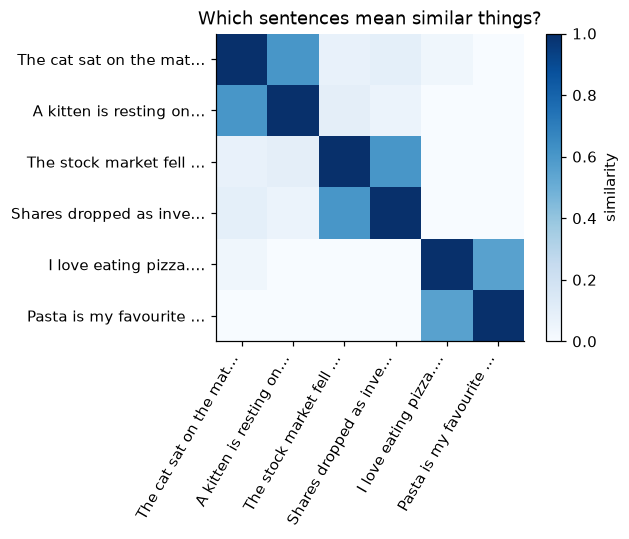

In [9]:
sim = emb @ emb.T                                        # similarity between every pair (1 = identical meaning)
short = [s[:22] + "…" for s in sentences]

plt.figure(figsize=(6.2, 5))
plt.imshow(sim, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(short)), short, rotation=60, ha="right"); plt.yticks(range(len(short)), short)
plt.colorbar(label="similarity"); plt.title("Which sentences mean similar things?")
plt.tight_layout(); plt.show()

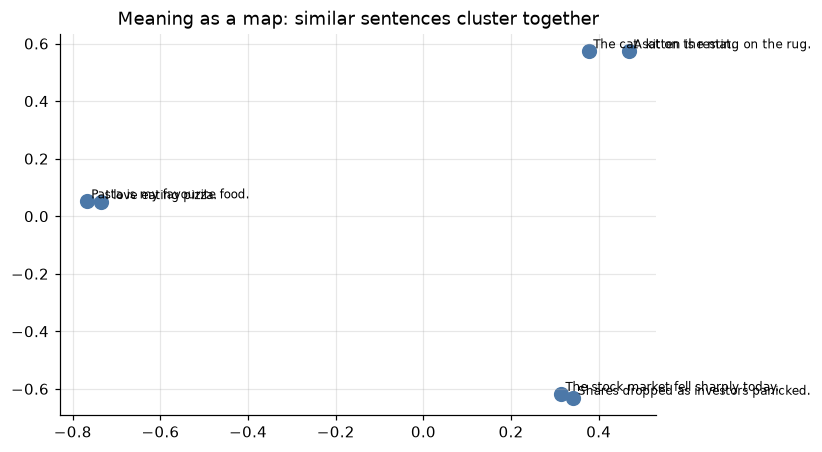

In [10]:
from sklearn.decomposition import PCA
pts = PCA(n_components=2).fit_transform(emb)             # squash 384 dimensions down to 2 so we can draw them
plt.figure(figsize=(7, 4.5))
for (x, y), s in zip(pts, sentences):
    plt.scatter(x, y, s=80, color=PALETTE[0]); plt.text(x + 0.01, y + 0.01, s, fontsize=8)
plt.title("Meaning as a map: similar sentences cluster together"); plt.grid(alpha=.3); plt.show()

In [11]:
# Semantic search: find the closest meaning, even with ZERO shared words
query = "a feline sleeping on a carpet"
q = embedder.encode([query], normalize_embeddings=True)[0]
best = int(np.argmax(emb @ q))
print(f"Query : {query}\nMatch : {sentences[best]}")

Query : a feline sleeping on a carpet
Match : A kitten is resting on the rug.


---
## 4️⃣ Attention: how words look at each other

Meaning depends on context. In:

> *"The animal didn't cross the street because **it** was too tired."*

what does **it** refer to? To figure that out, the model lets **every word look back at the other words** and decide *which ones matter most for understanding itself*. That mechanism is called **attention**.

Think of it as each word asking: *"Which other words should I pay attention to right now?"* and getting a set of weights (how much attention each earlier word gets).

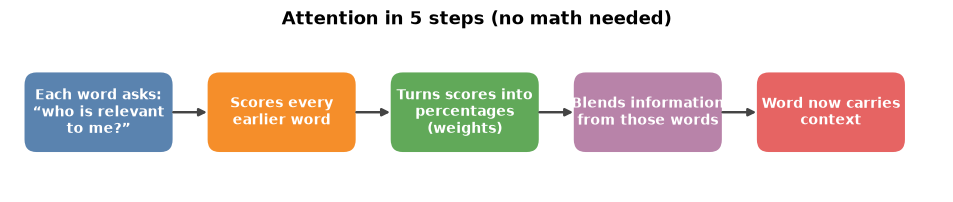

In [12]:
flow(["Each word asks:\n“who is relevant\nto me?”", "Scores every\nearlier word", "Turns scores into\npercentages (weights)",
      "Blends information\nfrom those words", "Word now carries\ncontext"],
     title="Attention in 5 steps (no math needed)", per_row=5, wrap=18)

Now let's look at **real attention weights from GPT-2**. Brighter square = that row's word is paying more attention to that column's word.

In [4]:
# def show_attention(sentence, layer=5):
#     ids = tok(sentence, return_tensors="pt")
#     with torch.no_grad():
#         out = gpt2(**ids, output_attentions=True)
#     tokens = [t.replace("Ġ", "") for t in tok.convert_ids_to_tokens(ids["input_ids"][0])]
#     att = out.attentions[layer][0].mean(0).numpy()          # average over the layer's attention heads
#     plt.figure(figsize=(6.5, 5.5))
#     plt.imshow(att, cmap="Blues")
#     plt.xticks(range(len(tokens)), tokens, rotation=60, ha="right"); plt.yticks(range(len(tokens)), tokens)
#     plt.xlabel("word being looked AT"); plt.ylabel("word doing the looking")
#     plt.title(f"Attention (GPT-2, layer {layer})"); plt.colorbar(); plt.tight_layout(); plt.show()

# show_attention("The animal didn't cross the street because it was too tired", layer=5)

**How to read it:** find the row for **it** and see which columns light up. Words can only look *backwards* (that's why the top-right is empty) — the model hasn't seen the future yet.

⚠️ Don't expect a tidy story: in real models, attention is spread across many "heads" and layers doing different jobs (grammar, position, copying, etc.). Try other layers:

In [5]:
# for L in [0, 5, 11]:
#     show_attention("The animal didn't cross the street because it was too tired", layer=L)

💬 **Discussion:** Early layers vs. late layers look different. What kinds of "jobs" might each be doing?

---
## 5️⃣ The Transformer architecture

All modern LLMs are built by stacking the same block many times. The block has just **two parts**:

1. **Attention** → words *share information* with each other
2. **Feed-forward network** → each word *thinks about* what it gathered

Stack the block 12 times (GPT-2 small) or ~100 times (the biggest models) and you get an LLM.

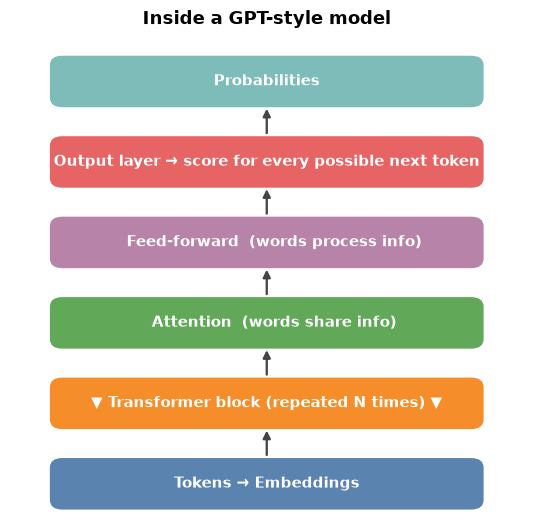

In [15]:
stack(["Tokens → Embeddings", "▼ Transformer block (repeated N times) ▼",
       "   Attention  (words share info)", "   Feed-forward  (words process info)",
       "Output layer → score for every possible next token", "Probabilities"],
      title="Inside a GPT-style model")

In [16]:
cfg = gpt2.config
n_params = sum(p.numel() for p in gpt2.parameters())
print(f"GPT-2 small:\n  layers (blocks stacked): {cfg.n_layer}\n  attention heads/layer  : {cfg.n_head}"
      f"\n  vector size            : {cfg.n_embd}\n  vocabulary size        : {cfg.vocab_size:,} tokens"
      f"\n  total parameters       : {n_params/1e6:.0f} million")

GPT-2 small:
  layers (blocks stacked): 12
  attention heads/layer  : 12
  vector size            : 768
  vocabulary size        : 50,257 tokens
  total parameters       : 124 million


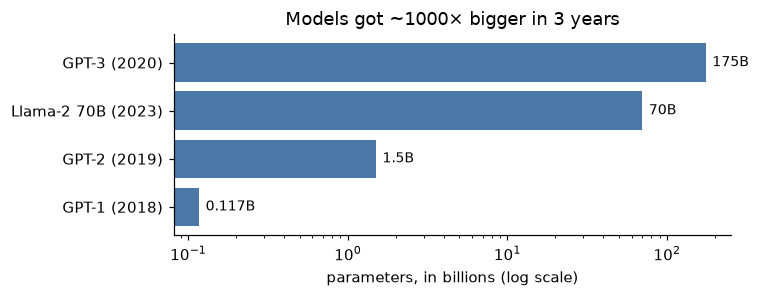

In [17]:
# How big have models become? (parameter counts, approximate, publicly reported)
models = {"GPT-1 (2018)": 0.117, "GPT-2 (2019)": 1.5, "Llama-2 70B (2023)": 70, "GPT-3 (2020)": 175}
names, sizes = zip(*sorted(models.items(), key=lambda kv: kv[1]))
plt.figure(figsize=(7, 2.8)); plt.barh(names, sizes, color=PALETTE[0]); plt.xscale("log")
plt.xlabel("parameters, in billions (log scale)"); plt.title("Models got ~1000× bigger in 3 years")
for i, s in enumerate(sizes): plt.text(s * 1.1, i, f"{s:g}B", va="center", fontsize=9)
plt.tight_layout(); plt.show()

**Parameters** = the adjustable numbers inside the model (like dials). Training = finding good settings for billions of dials.

---
## 6️⃣ Predicting the next word & controlling creativity

At every step the model scores **every token in its vocabulary** and turns those scores into probabilities. Let's look at what GPT-2 expects after a prompt.

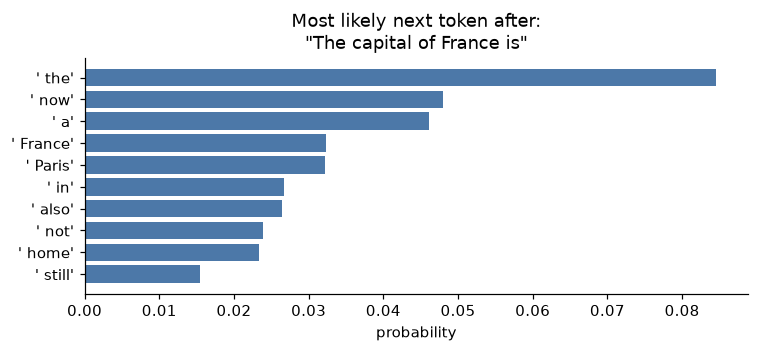

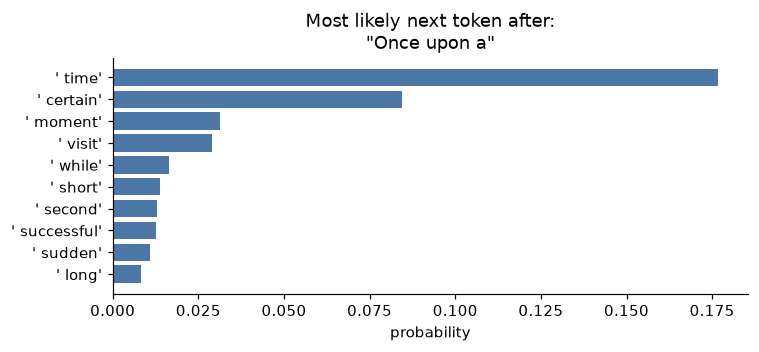

In [18]:
def next_token_probs(prompt, k=10):
    ids = tok(prompt, return_tensors="pt")
    with torch.no_grad():
        logits = gpt2(**ids).logits[0, -1]
    probs = torch.softmax(logits, dim=-1)
    top = torch.topk(probs, k)
    return [(tok.decode(int(i)), float(p)) for i, p in zip(top.indices, top.values)]

def plot_next(prompt, k=10):
    res = next_token_probs(prompt, k)
    plt.figure(figsize=(7, 3.3))
    plt.barh([repr(t) for t, _ in res][::-1], [p for _, p in res][::-1], color=PALETTE[0])
    plt.title(f'Most likely next token after:\n"{prompt}"'); plt.xlabel("probability")
    plt.tight_layout(); plt.show()

plot_next("The capital of France is")
plot_next("Once upon a")

### 🎛️ The creativity dial: temperature
After getting probabilities, the system must **pick** one. **Temperature** controls how adventurous that choice is:

- **Low (≈0.2)** → almost always picks the top choice → focused, repetitive
- **High (≈1.5+)** → gives unlikely tokens a real chance → creative, but can get weird

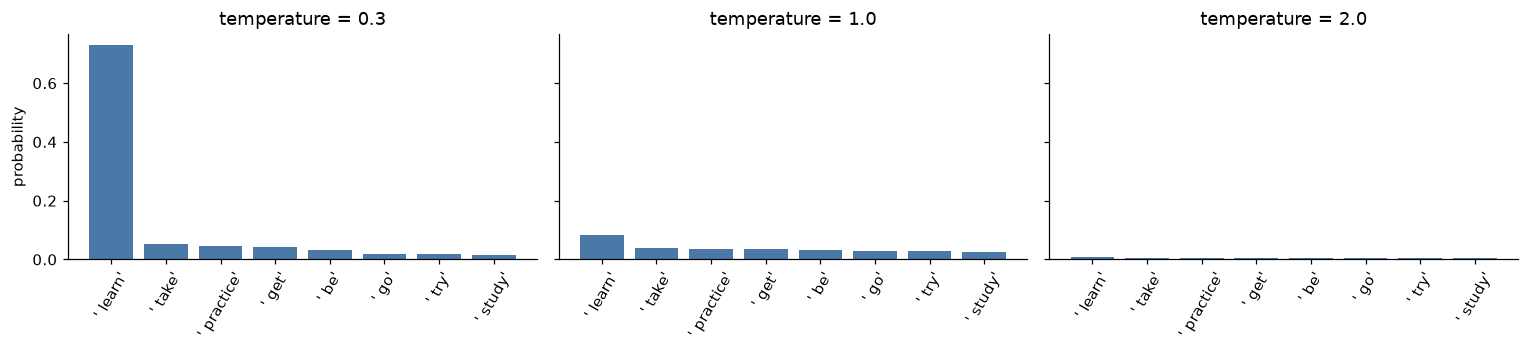

In [19]:
prompt = "The best way to learn something new is to"
ids = tok(prompt, return_tensors="pt")
with torch.no_grad():
    logits = gpt2(**ids).logits[0, -1]
top_ids = torch.topk(logits, 8).indices
labels = [repr(tok.decode(int(i))) for i in top_ids]

fig, axs = plt.subplots(1, 3, figsize=(14, 3.3), sharey=True)
for ax, T in zip(axs, [0.3, 1.0, 2.0]):
    p = torch.softmax(logits / T, dim=-1)[top_ids].numpy()
    ax.bar(labels, p, color=PALETTE[0]); ax.set_title(f"temperature = {T}"); ax.tick_params(axis="x", rotation=60)
axs[0].set_ylabel("probability"); plt.tight_layout(); plt.show()

In [20]:
prompt = "In the future, artificial intelligence will"

print("🔒 Greedy (always top choice):")
print(generator(prompt, max_new_tokens=30, do_sample=False)[0]["generated_text"], "\n")

for T in [0.3, 1.0, 1.8]:
    set_seed(3)
    print(f"🎲 temperature = {T}:")
    print(generator(prompt, max_new_tokens=30, do_sample=True, temperature=T, top_k=0)[0]["generated_text"], "\n")

🔒 Greedy (always top choice):


In the future, artificial intelligence will be able to do things like search for information about people, and to do things like search for information about people.

"We're going to 

🎲 temperature = 0.3:


In the future, artificial intelligence will be able to do things like pick up on the patterns of human behavior and learn to recognize patterns in other people.

"It's a very 

🎲 temperature = 1.0:


In the future, artificial intelligence will enable more efficiency, less inefficiency and fewer or fewer features that hinder human progress through process judgement.

That's because technology's innovation is a 

🎲 temperature = 1.8:


In the future, artificial intelligence will enable lidillanim tours in flash gaps Close Allan Bruce, senior IndivobyJob site mine meshes Private text sector forests transplocate sett ell Scriptureswestern 



Other common controls:
| Setting | Meaning |
|---|---|
| **top-k** | only consider the *k* most likely tokens |
| **top-p** | only consider the smallest group of tokens that together cover *p*% of probability |
| **max tokens** | stop after this many tokens |

💬 **Discussion:** When would you want low temperature? (e.g. data extraction, code) High? (e.g. brainstorming, poetry)

---
## 7️⃣ From raw model to chat assistant

GPT-2 is a **base model**: it only *continues text*. It doesn't know it's supposed to answer you. Assistants like ChatGPT or Claude go through more training stages.

D:\Sunday_Office_Class\class_10_8_26_AI LLM Foundations\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128640 (\N{ROCKET}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


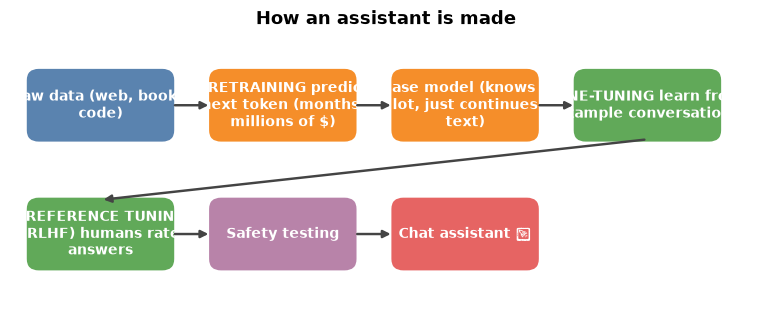

In [21]:
flow(["Raw data\n(web, books, code)", "PRETRAINING\npredict next token\n(months, millions of $)", "Base model\n(knows a lot,\njust continues text)",
      "FINE-TUNING\nlearn from example\nconversations", "PREFERENCE TUNING\n(RLHF) humans rate\nanswers", "Safety testing", "Chat assistant 🚀"],
     title="How an assistant is made", per_row=4, wrap=22,
     colors=["#4C78A8", "#F58518", "#F58518", "#54A24B", "#54A24B", "#B279A2", "#E45756"])

| Stage | What it adds |
|---|---|
| **Pretraining** | knowledge & language skill |
| **Instruction fine-tuning** | follows instructions instead of rambling on |
| **RLHF / preference tuning** | helpful, polite, safer style (humans compare answers; the model learns what people prefer) |

### See the difference: base model vs. assistant model

In [22]:
question = "What is the capital of France? Answer briefly."
set_seed(0)
print("🤖 BASE model (GPT-2) just continues the text:\n")
print(generator(question, max_new_tokens=40, do_sample=True, temperature=0.7)[0]["generated_text"])

🤖 BASE model (GPT-2) just continues the text:



What is the capital of France? Answer briefly. The French capital is the capital of France, the capital of the whole world.

This is the capital of the whole world. Our capital is the capital of France.

This is the


In [7]:
# An instruction-tuned small model (≈1 GB download — optional)
chat = pipeline("text-generation", model="Qwen/Qwen2.5-0.5B-Instruct", model_kwargs={"cache_dir": str(MODEL_CACHE)})
messages = [{"role": "user", "content": question}]
reply = chat(messages, max_new_tokens=60)[0]["generated_text"][-1]["content"]
print("💬 INSTRUCTION-TUNED model answers the question:\n")
print(reply)

NameError: name 'pipeline' is not defined

**Under the hood:** a "chat" is still just next-token prediction — the conversation is flattened into one long text with special markers, and the model continues it.

In [6]:
messages = [{"role": "system", "content": "You are a helpful tutor."},
            {"role": "user", "content": "What is attention?"}]
print(chat.tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True))

NameError: name 'chat' is not defined

💬 **Discussion:** Why do you think humans rating answers (RLHF) improves usefulness beyond just training on more text?

---
## 8️⃣ Scale: size, memory, cost 🔷

**Scaling laws:** bigger models + more data + more compute → predictably better. That's why labs spend so much on training.

**But running** big models needs lots of memory, because every parameter must be stored.

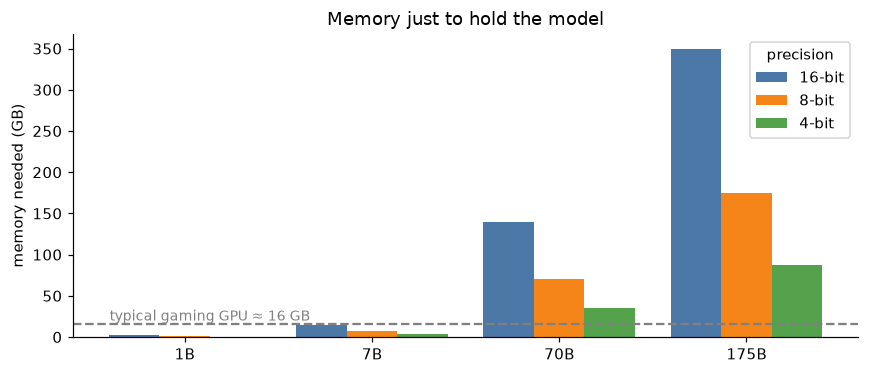

In [25]:
def memory_gb(billions_of_params, precision="16-bit"):
    bytes_per = {"16-bit": 2, "8-bit": 1, "4-bit": 0.5}[precision]
    return billions_of_params * bytes_per          # billions of params × bytes each = GB

sizes = [1, 7, 70, 175]
x = np.arange(len(sizes)); wd = 0.27
plt.figure(figsize=(8, 3.5))
for k, prec in enumerate(["16-bit", "8-bit", "4-bit"]):
    plt.bar(x + (k - 1) * wd, [memory_gb(s, prec) for s in sizes], wd, label=prec, color=PALETTE[k])
plt.xticks(x, [f"{s}B" for s in sizes]); plt.ylabel("memory needed (GB)")
plt.axhline(16, ls="--", color="gray"); plt.text(-0.4, 20, "typical gaming GPU ≈ 16 GB", color="gray", fontsize=9)
plt.title("Memory just to hold the model"); plt.legend(title="precision"); plt.tight_layout(); plt.show()

**Quantization** (storing numbers with fewer bits) is how people squeeze big models onto smaller hardware, at a small cost in quality.

**Context window** = how much text the model can consider at once. Longer context also costs more memory and compute.

---
## 9️⃣ Limitations: why LLMs get things wrong

| Problem | Why it happens |
|---|---|
| **Hallucination** | It's trained to produce *plausible* text, not to *verify truth* |
| **Can't count letters well** | It sees tokens, not individual letters |
| **Outdated knowledge** | Weights are frozen at training time |
| **Limited context** | Can only consider so much text at once |
| **Prompt injection** | Instructions and data are mixed in one text stream |
| **Bias** | Learned from human-written text |

In [26]:
# Why letter-counting is hard: the model never "sees" letters
for w in ["strawberry", "unbelievable"]:
    pieces = [enc.decode([i]) for i in enc.encode(w)]
    print(f"{w!r} is seen as → {pieces}")

'strawberry' is seen as → ['str', 'aw', 'berry']
'unbelievable' is seen as → ['un', 'belie', 'vable']


In [27]:
# Fluent ≠ true: GPT-2 will confidently continue ANY prompt
for p in ["The first person to walk on Mars was", "The inventor of the light bulb was"]:
    top = next_token_probs(p, 4)
    print(p, "→", [(t, f"{pr:.0%}") for t, pr in top])
print("\nProbability = 'how plausible is this continuation', NOT 'is this fact correct'.")

The first person to walk on Mars was → [(' a', '11%'), (' the', '5%'), (' an', '2%'), (' Neil', '1%')]
The inventor of the light bulb was → [(' a', '16%'), (' an', '4%'), (' the', '4%'), (' Dr', '2%')]

Probability = 'how plausible is this continuation', NOT 'is this fact correct'.


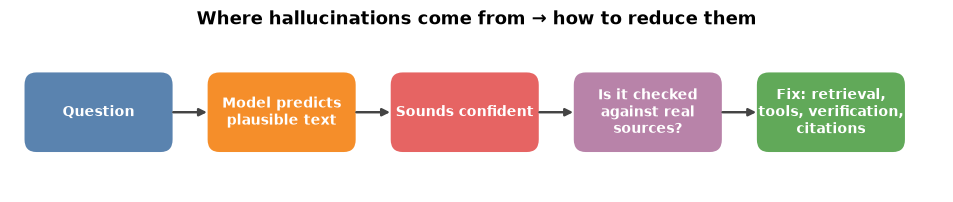

In [28]:
flow(["Question", "Model predicts\nplausible text", "Sounds confident", "Is it checked\nagainst real sources?",
      "Fix: retrieval, tools,\nverification, citations"],
     title="Where hallucinations come from → how to reduce them", per_row=5, wrap=20,
     colors=[PALETTE[0], PALETTE[1], PALETTE[4], PALETTE[3], PALETTE[2]])

💬 **Discussion:** For which tasks is "plausible but sometimes wrong" acceptable? For which is it dangerous?

---
## 🔟 RAG & agents: making LLMs more useful 🔷

### RAG — Retrieval-Augmented Generation
Instead of trusting the model's memory, **look up relevant documents first** and put them in the prompt. This reduces hallucination and lets the model use *your* private/up-to-date data.

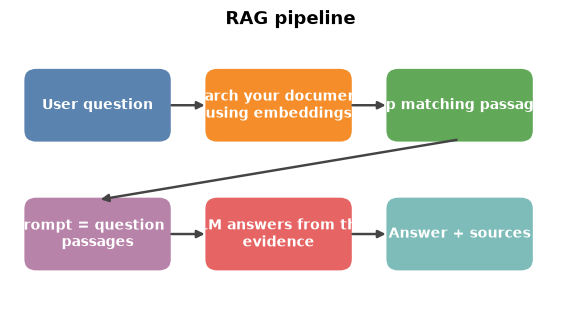

In [29]:
flow(["User question", "Search your documents\n(using embeddings)", "Top matching passages",
      "Prompt = question\n+ passages", "LLM answers from\nthe evidence", "Answer + sources"],
     title="RAG pipeline", per_row=3, wrap=22)

In [30]:
# A mini knowledge base (imagine company policies, manuals, wiki pages…)
docs = [
 "Employees get 25 days of paid vacation per year, plus public holidays.",
 "Expense reports must be submitted within 30 days with receipts attached.",
 "Remote work is allowed up to three days per week with manager approval.",
 "The company laptop must be encrypted and updated every month.",
 "Health insurance covers employees and their immediate family members.",
]
doc_emb = embedder.encode(docs, normalize_embeddings=True)

def retrieve(question, k=2):
    q = embedder.encode([question], normalize_embeddings=True)[0]
    order = np.argsort(-(doc_emb @ q))[:k]
    return [docs[i] for i in order]

question = "How many days can I work from home?"
found = retrieve(question)
print("📚 Retrieved:"); [print("  -", d) for d in found]

prompt = ("Answer using ONLY this context.\n\nContext:\n" + "\n".join(f"- {d}" for d in found)
          + f"\n\nQuestion: {question}")
print("\n📨 Prompt that would be sent to the LLM:\n" + prompt)

📚 Retrieved:
  - Remote work is allowed up to three days per week with manager approval.
  - Employees get 25 days of paid vacation per year, plus public holidays.

📨 Prompt that would be sent to the LLM:
Answer using ONLY this context.

Context:
- Remote work is allowed up to three days per week with manager approval.
- Employees get 25 days of paid vacation per year, plus public holidays.

Question: How many days can I work from home?


### Tools & agents
LLMs can't browse, calculate, or access your files on their own — but they can **ask for a tool to be used**. Your code runs the tool and returns the result. Repeat until done: that loop is an **agent**.

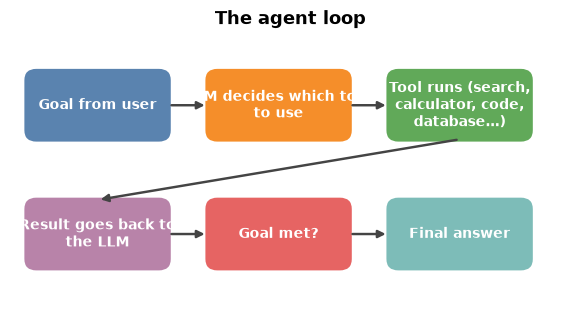

In [31]:
flow(["Goal from user", "LLM decides\nwhich tool to use", "Tool runs\n(search, calculator,\ncode, database…)", "Result goes back\nto the LLM", "Goal met?", "Final answer"],
     title="The agent loop", per_row=3, wrap=22)

### (Optional) Calling a hosted model via API
Set RUN_ANTHROPIC_DEMO=1, ANTHROPIC_API_KEY, and ANTHROPIC_MODEL to enable this paid demo. It is skipped by default. Never paste keys into shared notebooks.

In [32]:
# Optional paid API demo: explicitly enable it and configure credentials.
import os

if os.environ.get('RUN_ANTHROPIC_DEMO') != '1':
    print('Skipped optional API demo. Set RUN_ANTHROPIC_DEMO=1 to enable.')
elif not os.environ.get('ANTHROPIC_API_KEY') or not os.environ.get('ANTHROPIC_MODEL'):
    print('Set ANTHROPIC_API_KEY and ANTHROPIC_MODEL to an available model ID first.')
else:
    import anthropic
    client = anthropic.Anthropic()
    resp = client.messages.create(
        model=os.environ['ANTHROPIC_MODEL'], max_tokens=300,
        messages=[{'role': 'user', 'content': 'Explain what an LLM is in 3 sentences for a beginner.'}],
    )
    print(''.join(block.text for block in resp.content if block.type == 'text'))
    print('Tokens used: input:', resp.usage.input_tokens, '| output:', resp.usage.output_tokens)


Skipped optional API demo. Set RUN_ANTHROPIC_DEMO=1 to enable.


---
## 1️⃣1️⃣ Recap & exercises

```
text → tokens → embeddings → [ attention + feed-forward ] × many layers → probabilities → pick next token → repeat
```

### Key takeaways
1. An LLM predicts the next **token**; generation is just doing that in a loop.
2. **Tokens** decide cost, context limits, and some blind spots.
3. **Embeddings** turn tokens into meaning-carrying numbers.
4. **Attention** lets words use context from other words.
5. **Pretraining** gives knowledge; **fine-tuning + RLHF** make it a helpful assistant.
6. **Temperature** etc. change behaviour without changing the model.
7. LLMs sound confident even when wrong → ground them with **RAG, tools, and checking**.

### 🧪 Try it yourself
1. Compare token counts of your own name, a paragraph in your language, and a code snippet.
2. In section 3, add 3 new sentences. Do similar ones cluster together?
3. In section 4, try your own sentence with a pronoun. Which layer seems most "interesting"?
4. In section 6, find a prompt where greedy decoding repeats itself; fix it using temperature.
5. In section 7, ask the instruction-tuned model something harder. Where does it fail?
6. In section 10, add your own documents and questions. Find a question where retrieval picks the wrong passage.

### 📚 Go deeper
- Jay Alammar — *The Illustrated Transformer* (visual, beginner-friendly)
- 3Blue1Brown — *Neural Networks* video series (the "Transformers" chapters)
- Andrej Karpathy — *Intro to Large Language Models* (1-hour talk)
- Hugging Face — free *LLM Course* (huggingface.co/learn)

### 🔤 Mini glossary
**Token** – a chunk of text · **Embedding** – meaning as numbers · **Parameter** – an adjustable number in the model · **Context window** – how much text it can consider at once ·
**Inference** – using a trained model · **Fine-tuning** – extra training on specific data · **Hallucination** – confident but false output · **RAG** – look things up, then answer